# Детекция аномалий в налоговых декларациях: сравнение методов без учителя

Ноутбук к статье «Применение методов машинного обучения для детекции аномалий в налоговых декларациях»
(Дубанаев З. М., КГТУ им. И. Раззакова). Он шаг за шагом проходит всё исследование: данные,
методы, оценку качества и анализ результатов.

**Содержание**
1. Подготовка
2. Данные: генератор деклараций и внедрение аномалий
3. Разбиение и предобработка
4. Методы детекции
5. Как оценивается качество, если модели обучаются без меток
6. Основные эксперименты
7. ROC- и PR-кривые
8. Какие типы аномалий находит каждый метод
9. Почему проигрывает Isolation Forest
10. Выводы и ограничения

Весь код находится в `experiments.py`; здесь он вызывается по шагам. Все случайные значения
фиксированы, поэтому при повторном запуске получаются те же числа.

## 1. Подготовка

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display
import os
import experiments as ex

os.makedirs("figures", exist_ok=True)   # сюда сохраняются рисунки

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 2. Данные

### 2.1. Генератор синтетических деклараций

Реальные данные налогоплательщиков не используются. Генератор воспроизводит структуру
Единой налоговой декларации организаций КР (форма STI 101). Для каждой из восьми отраслей заданы
выработка на одного работника, доля расходов и материальных затрат, средняя зарплата и
фондоёмкость. Эти параметры — **экспертные предположения автора**, по реальным данным они
не калибровались. Налоги считаются по действующим ставкам: НДС 12 %, налог на прибыль 10 %.

Сформированы три набора с разным профилем налогоплательщиков:

| Набор | Размер | Особенность |
|---|---|---|
| `vat` | 7 850 | плательщики НДС общего режима |
| `profit` | 6 280 | тяжелохвостое распределение размера предприятий |
| `mixed` | 4 290 | смесь режимов: общий, единый налог, патент |

In [2]:
rng = np.random.default_rng(0)
clean = ex.generate(7850, "vat", rng)
print("Признаков:", len(ex.NUM_FEATURES), "числовых +", len(ex.CAT_FEATURES), "категориальных")
clean[["industry", "regime", "headcount", "revenue", "payroll",
       "payroll_per_employee", "vat_out", "vat_in", "deduction_share"]].head()

Признаков: 21 числовых + 3 категориальных


,industry,regime,headcount,revenue,payroll,payroll_per_employee,vat_out,vat_in,deduction_share
0,сельское_хоз,общий,12.0,6.792356e+06,2.078938e+06,173244.852349,8.150828e+05,3.197314e+05,0.392269
1,общепит,общий,9.0,6.728477e+06,2.541668e+06,282407.538400,8.074172e+05,2.741128e+05,0.339493
2,транспорт,общий,37.0,7.339277e+07,1.228707e+07,332082.882927,8.807133e+06,2.828314e+06,0.321139
3,производство,общий,13.0,2.547572e+07,3.298249e+06,253711.492602,3.057086e+06,1.169079e+06,0.382416
4,производство,общий,18.0,4.379665e+07,7.630025e+06,423890.302348,5.255598e+06,2.856267e+06,0.543471


### 2.2. Внедрение аномалий

В 2,1 % деклараций внедряются аномалии трёх типов, поровну:

| Тип | Что меняется | Что имитирует |
|---|---|---|
| точечное искажение | одна строка (выручка, расходы, материальные затраты или ОС) умножается на 0,1–0,3 или 3–8, зависимые строки не пересчитываются | ошибку заполнения, занижение строки |
| завышение вычетов НДС | входной НДС × 1,3–2, НДС к уплате и доля вычетов пересчитаны согласованно | фиктивные ЭСФ |
| занижение ФОТ | ФОТ × 0,2–0,5 при той же численности, взносы пересчитаны | выплату зарплат «в конвертах» |

Поскольку аномалии внедряем мы сами, для каждой декларации известна метка `label`
(1 — аномалия) и тип `anomaly_type`.

In [3]:
df, tr, te, tr_l, te_l, Xtr, Xte = ex.prepare("vat", 7850, seed=0)
print("Всего деклараций:", len(df), "| аномалий:", df.label.sum())
df.anomaly_type.value_counts()

Всего деклараций: 7850 | аномалий: 165


anomaly_type
нет              7685
точечная           55
вычеты_НДС         55
занижение_ФОТ      55
Name: count, dtype: int64

Пример: несколько деклараций с заниженным ФОТ. ФОТ на одного работника у них заметно ниже, чем у нормальных деклараций той же отрасли.

In [4]:
fot = df[df.anomaly_type == "занижение_ФОТ"].head(3)
typical = df[df.label == 0].groupby("industry").payroll_per_employee.median().rename("медиана по отрасли")
fot[["industry", "headcount", "payroll_per_employee"]].join(typical, on="industry")

,industry,headcount,payroll_per_employee,медиана по отрасли
253,услуги,89.0,84905.288261,335600.781097
396,общепит,9.0,70040.531750,240529.229718
427,общепит,52.0,96372.195426,240529.229718


### 2.3. Как выглядят аномалии (рисунок 1)

Слева — численность и ФОТ на одного работника, справа — выручка и доля вычетов по НДС.
Значительная часть деклараций с заниженным ФОТ лежит ниже основного облака, а с завышенными
вычетами — выше; точечные искажения в этих проекциях почти не видны.

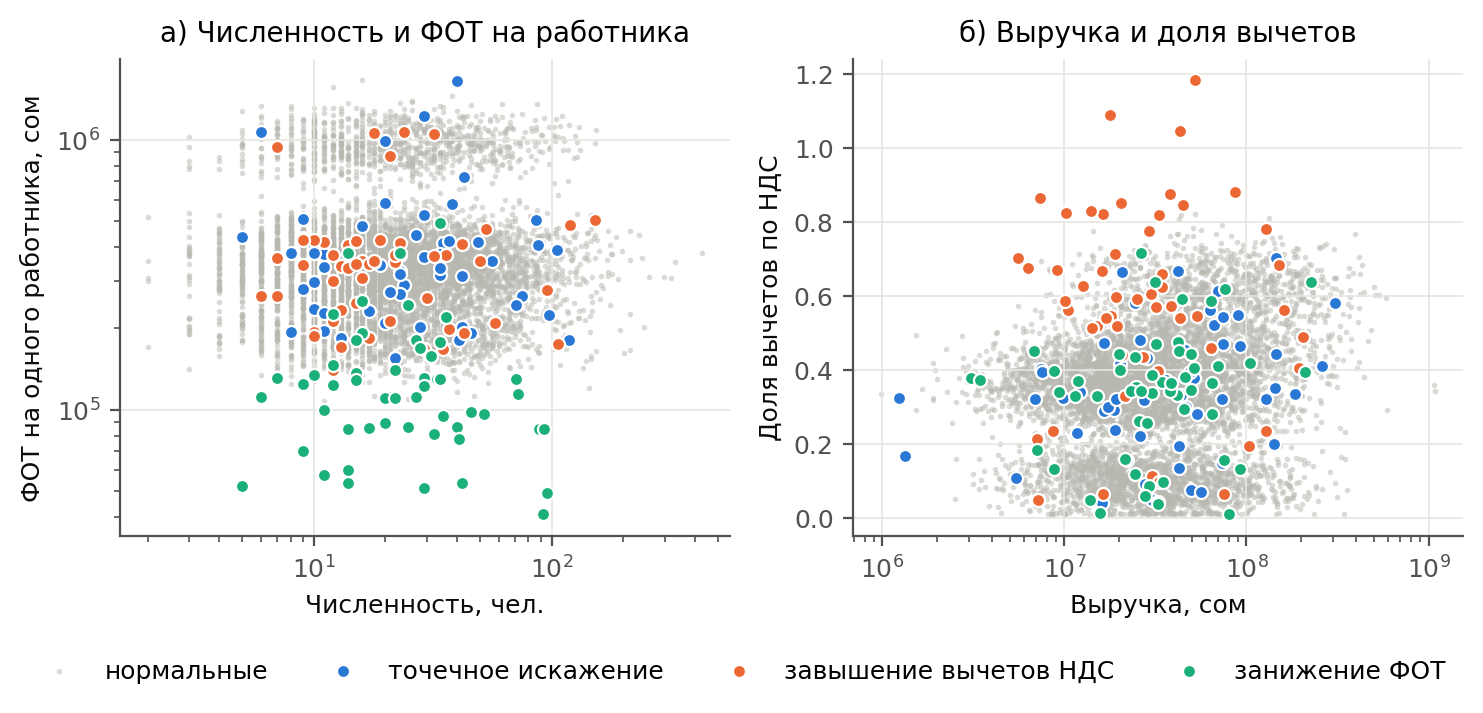

In [5]:
ex.fig1_data()
display(Image("figures/fig1_data.png"))

## 3. Разбиение и предобработка

- Набор делится на обучающую (70 %) и тестовую (30 %) части со стратификацией по метке.
- Денежные признаки преобразуются как sign(x)·ln(1 + |x|): суммы отличаются на порядки.
- Числовые признаки стандартизируются, категориальные кодируются one-hot.
- Все параметры преобразований оцениваются только по обучающей части.

In [6]:
print("Обучающая часть:", Xtr.shape, "| тестовая часть:", Xte.shape)
print("Аномалий в тестовой части:", int(te.label.sum()))

Обучающая часть: (5495, 39) | тестовая часть: (2355, 39)
Аномалий в тестовой части: 49


## 4. Методы детекции

Методы сгруппированы по принципу, на котором основана оценка аномальности:

| Группа | Метод | Идея |
|---|---|---|
| статистический | Z-скоринг (бенчмарк) | максимум модулей z-оценок логарифма выручки и доли вычетов — аналог пороговых правил |
| изоляция (деревья) | Isolation Forest | случайные разбиения по одному признаку; чем быстрее наблюдение изолируется, тем оно аномальнее |
| плотность / близость | LOF | сравнивает локальную плотность вокруг точки с плотностью у её соседей |
| граница области | One-Class SVM | строит границу области «нормальных» наблюдений |
| глубокое обучение | автокодер | сеть d → 16 → 8 → 16 → d учится восстанавливать декларацию; ошибка восстановления = оценка |
| ансамбль | среднее | нормированные оценки четырёх ML-методов усредняются с равными весами |

In [7]:
pd.Series(ex.METHOD_GROUP, name='группа').to_frame()

,группа
Z-скоринг (бенчмарк),статистический
Isolation Forest,изоляция (деревья)
LOF,плотность / близость
One-Class SVM,граница области
Автокодер,глубокое обучение
Ансамбль (среднее),ансамбль


## 5. Как оценивается качество, если модели обучаются без меток

Это ключевой момент. **Модели не видят меток**: на обучающей части они изучают, как выглядят
декларации, и выдают для каждой декларации оценку аномальности. Аномалии в обучающей части
остаются — как и в реальной жизни, где никто заранее не знает, какие декларации искажены.

Метки известны только потому, что аномалии внедрили мы сами. Они используются **один раз, в конце**:
чтобы сравнить оценки моделей с истиной на тестовой части. Это как ответы в конце задачника:
решаем без них, проверяем по ним.

- Декларация считается отмеченной, если её оценка входит в **верхние 3 %**. Отсюда Precision, Recall, F1.
- **ROC-AUC** и **PR-AUC** оценивают ранжирование целиком, без порога. При доле аномалий 2,1 %
  PR-AUC информативнее: у случайного ранжирования он равен примерно 0,02.

In [8]:
y = te.label.values
scores = ex.all_scores(tr_l, te_l, Xtr, Xte, seed=0)
pd.DataFrame({m: ex.evaluate(y, s, 0.03) for m, s in scores.items()}).T.round(3)

,Precision,Recall,F1,ROC_AUC,PR_AUC
Isolation Forest,0.028,0.041,0.033,0.594,0.028
Автокодер,0.099,0.143,0.117,0.805,0.086
LOF,0.197,0.286,0.233,0.868,0.132
One-Class SVM,0.042,0.061,0.050,0.723,0.055
Ансамбль (среднее),0.141,0.204,0.167,0.812,0.088
Z-скоринг (бенчмарк),0.085,0.122,0.100,0.578,0.069


## 6. Основные эксперименты

Каждый из трёх экспериментов повторяется 5 раз с разными начальными значениями генератора
(меняются данные, разбиение и инициализация моделей). Ниже — средние значения и стандартные
отклонения. Запуск занимает несколько минут.

In [9]:
raw = ex.run_all()


=== Эксперимент 1. Декларации по НДС (n=7850, 5 запусков) ===
                                          Precision        Recall            F1        ROC_AUC        PR_AUC       
                                               mean    std   mean    std   mean    std    mean    std   mean    std
method               group                                                                                         
LOF                  плотность / близость     0.228  0.044  0.329  0.064  0.270  0.052   0.867  0.023  0.193  0.058
Автокодер            глубокое обучение        0.220  0.095  0.316  0.134  0.259  0.111   0.864  0.042  0.190  0.086
Ансамбль (среднее)   ансамбль                 0.189  0.054  0.272  0.078  0.223  0.064   0.830  0.048  0.136  0.043
One-Class SVM        граница области          0.115  0.055  0.167  0.080  0.136  0.065   0.727  0.060  0.087  0.034
Z-скоринг (бенчмарк) статистический           0.099  0.022  0.142  0.031  0.116  0.026   0.583  0.017  0.104  0.035
Isolation

Сводка: F1 и ROC-AUC по экспериментам (среднее по 5 запускам).

In [10]:
summary = (raw.groupby(["experiment", "method"])[["F1", "ROC_AUC", "PR_AUC"]].mean()
              .unstack(0).round(3))
summary.sort_values(("ROC_AUC", "1. Декларации по НДС"), ascending=False)

F1                                                                    ROC_AUC                                     \
experiment           1. Декларации по НДС 2. Декларации по налогу на прибыль 3. Смешанный набор 1. Декларации по НДС 2. Декларации по налогу на прибыль   
method                                                                                                                                                    
LOF                                 0.270                              0.305              0.164                0.867                              0.876   
Автокодер                           0.259                              0.243              0.145                0.864                              0.859   
Ансамбль (среднее)                  0.223                              0.256              0.139                0.830                              0.851   
One-Class SVM                       0.136                              0.161              0.109                0.727                              0.750   
Isolation Forest                    0.043                              0.041              0.024                0.596                              0.613   
Z-скоринг (бенчмарк)                0.116                              0.111              0.139                0.583                              0.608   

                                                      PR_AUC                                                        
experiment           3. Смешанный набор 1. Декларации по НДС 2. Декларации по налогу на прибыль 3. Смешанный набор  
method                                                                                                              
LOF                               0.832                0.193                              0.210              0.117  
Автокодер                         0.842                0.190                              0.189              0.111  
Ансамбль (среднее)                0.814                0.136                              0.158              0.093  
One-Class SVM                     0.738                0.087                              0.096              0.068  
Isolation Forest                  0.617                0.031                              0.034              0.033  
Z-скоринг (бенчмарк)              0.607                0.104                              0.064              0.090

## 7. ROC- и PR-кривые (рисунок 2)

Набор 1, один запуск. LOF и автокодер лежат выше остальных на ROC-кривой; кривая
Isolation Forest близка к диагонали, то есть к случайному ранжированию.

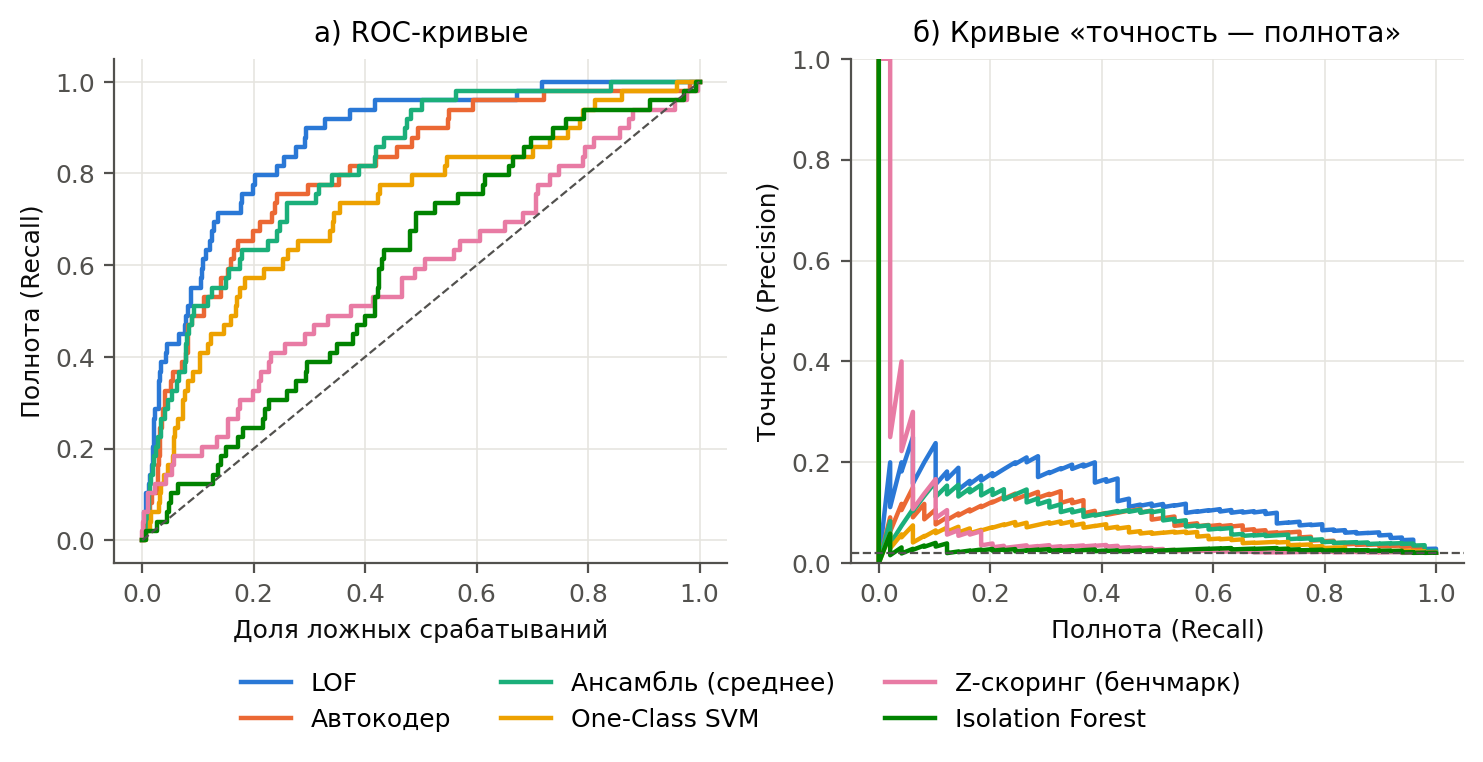

In [11]:
ex.fig2_curves()
display(Image("figures/fig2_curves.png"))

## 8. Какие типы аномалий находит каждый метод (рисунок 3)

Полнота (Recall) отдельно по типам аномалий, среднее по трём экспериментам и пяти запускам.
Здесь же — несколько диагностических проверок, которые используются в обсуждении статьи.

In [12]:
recall_table = ex.additional_analysis()


=== Recall по типам аномалий и ROC-AUC, среднее по 3 экспериментам и 5 запускам (все признаки) ===
               Isolation Forest  Автокодер    LOF  One-Class SVM
anomaly_type                                                    
вычеты_НДС                0.047      0.293  0.243          0.155
занижение_ФОТ             0.059      0.230  0.534          0.283
точечная                  0.038      0.244  0.120          0.061
ROC_AUC                   0.609      0.855  0.859          0.738

=== Recall по типам аномалий и ROC-AUC, среднее по 3 экспериментам и 5 запускам (без категориальных признаков) ===
               Isolation Forest  Автокодер    LOF  One-Class SVM
anomaly_type                                                    
вычеты_НДС                0.047      0.271  0.223          0.155
занижение_ФОТ             0.030      0.170  0.489          0.273
точечная                  0.046      0.410  0.173          0.074
ROC_AUC                   0.630      0.838  0.864          0.735

===

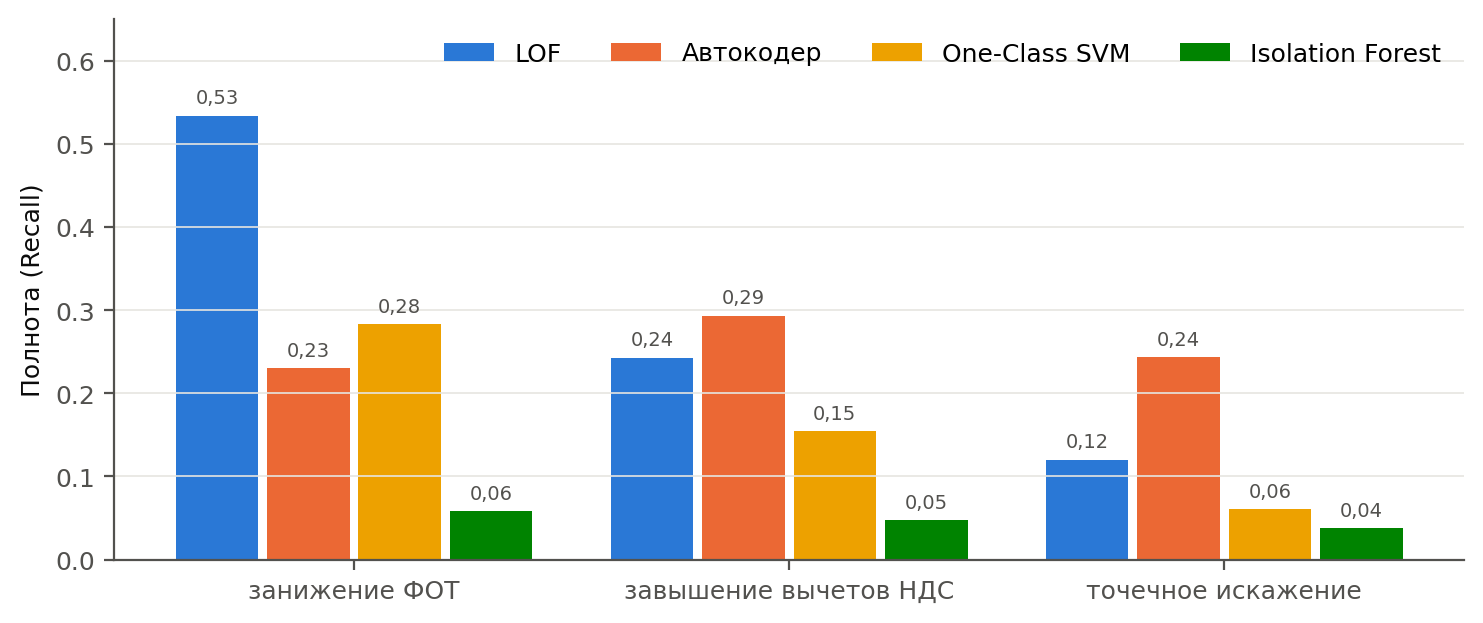

In [13]:
ex.fig3_recall_by_type(recall_table)
display(Image("figures/fig3_recall_by_type.png"))

## 9. Почему проигрывает Isolation Forest (рисунок 4)

По горизонтали — насколько масштаб предприятия (логарифм выручки) удалён от среднего,
по вертикали — оценка Isolation Forest. Оценка растёт вместе с удалённостью масштаба:
выше порога оказываются в основном самые крупные и самые мелкие **нормальные** предприятия,
а большинство аномалий остаётся ниже порога.

Возможное объяснение: около 16 из 40 признаков — денежные суммы, которые растут вместе
с размером предприятия. Случайные разбиения чаще всего приходятся на них, поэтому быстрее
всего изолируются предприятия необычного размера. Если оставить только признаки-отношения,
ROC-AUC Isolation Forest растёт лишь до 0,63–0,72, так что это объяснение неполное.

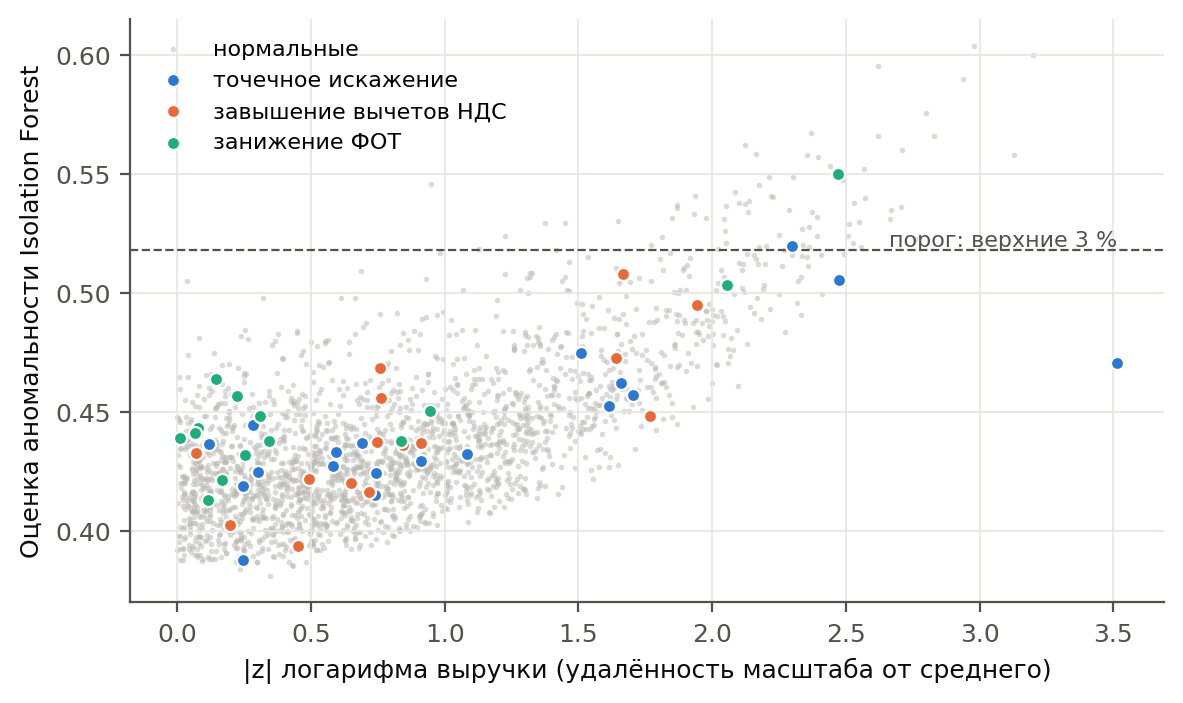

In [14]:
ex.fig4_iforest_size()
display(Image("figures/fig4_iforest_size.png"))

## 10. Выводы и ограничения

**Выводы**
- Лучшие результаты во всех трёх экспериментах — у LOF и автокодера (ROC-AUC 0,83–0,88).
- Isolation Forest близок к случайному ранжированию (ROC-AUC около 0,6): его оценка
  определяется в основном масштабом предприятия.
- Ансамбль с равными весами не превзошёл лучшие одиночные методы.
- LOF лучше выявляет занижение ФОТ, автокодер — завышение вычетов и точечные искажения.

**Ограничения**
- Данные и аномалии синтетические; параметры генератора — экспертные предположения.
- Гиперпараметры не подбирались, порог фиксирован (верхние 3 %).
- Для практических выводов нужна проверка на реальных обезличенных данных.